# CNN Image Classification on the Flowers Dataset
**Name:** Rakibul Hasan  **ID:** 23-55500-3  **Course:** CVPR  **Section:** E  
Goal: design and train a custom CNN to classify flower images into 5 classes using PyTorch.

## 1. Import Libraries
PyTorch and torchvision are used for data loading, transforms and the model. NumPy and Matplotlib handle numeric work and plotting. The notebook uses a GPU when available.

In [1]:
# Import libraries and select GPU if available, otherwise CPU
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, Subset
import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


## 2. Load and Explore the Dataset
**Dataset:** Flowers Recognition (Kaggle, alxmamaev/flowers-recognition).               
**Classes (5):** daisy, dandelion, rose, sunflower, tulip.     
**Size:** 4,317 RGB images of different sizes, stored in one folder per class. The dataset has no predefined train/test split, so I split it myself.   
**Split:** 70% train (3,021), 15% validation (647), 15% test (649).
The validation set is used to monitor training, and the test set is used only once at the end.

In [2]:
# Download the Flowers Recognition dataset from Kaggle
import kagglehub, os
path = kagglehub.dataset_download("alxmamaev/flowers-recognition")
print("Path to dataset files:", path)
print(os.listdir(path))

Using Colab cache for faster access to the 'flowers-recognition' dataset.
Path to dataset files: /kaggle/input/flowers-recognition
['flowers']


## 3. Preprocessing and Augmentation
- **Resize to 64x64:** the images have different sizes, and a fixed size is needed for the CNN. 64x64 keeps enough detail while training quickly.
- **ToTensor:** converts images to tensors and scales pixel values to [0, 1].
- **Augmentation (training only):** random horizontal flip, random rotation (±15°) and color jitter. This creates more variety and helps reduce overfitting on a small dataset.
- **No augmentation for validation/test**, so they measure performance on the real images.
- The same folder is loaded twice so that only the training copy is augmented. A fixed seed (42) makes the split reproducible.

In [3]:
# Resize to 64x64; augmentation only for training data; ToTensor scales pixels to [0,1]
size = 64
train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

data_folder = path + '/flowers'

# same folder loaded twice so only the training copy gets augmentation
train_full = datasets.ImageFolder(data_folder, transform=train_transform)
eval_full  = datasets.ImageFolder(data_folder, transform=val_transform)

# 70/15/15 random split with a fixed seed (42) so results are reproducible
g = torch.Generator().manual_seed(42)
idx = torch.randperm(len(train_full), generator=g).tolist()
n_train = int(0.70 * len(idx))
n_val   = int(0.15 * len(idx))

train_data = Subset(train_full, idx[:n_train])
val_data   = Subset(eval_full,  idx[n_train:n_train + n_val])
test_data  = Subset(eval_full,  idx[n_train + n_val:])

In [4]:
# Print split sizes and class-to-index mapping
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classes and Indices: ', train_full.class_to_idx)

Dataset Summary
Train Data:  3021
Validation Data:  647
Test Data:  649
Classes and Indices:  {'daisy': 0, 'dandelion': 1, 'rose': 2, 'sunflower': 3, 'tulip': 4}


## Hyperparameters
| Parameter | Value | Rationale |
|---|---|---|
| Image size | 64x64 | Small enough to train quickly, large enough to keep flower shapes and colors |
| Batch size | 32 | Gives stable gradient updates and fits comfortably in memory |
| Optimizer | Adam | Adapts the learning rate per parameter and converges quickly with little tuning |
| Learning rate | 1e-3 | Standard default for Adam; training loss decreased steadily with it |
| Loss | Cross-entropy | Standard loss for multi-class classification |
| Epochs | 20 | Validation loss stopped improving around epochs 12 to 16, so 20 epochs is enough to see convergence and the start of overfitting |
| Split | 70/15/15 | Enough training data while keeping reasonable validation and test sets |
| Augmentation | flip, ±15° rotation, color jitter | Reduces overfitting on a small dataset |

In [5]:
# Hyperparameters
batch_size = 32
learning_rate = 1e-3
epoch_number = 20

In [6]:
# DataLoaders: shuffle only the training set
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

## 4. CNN Architecture
The model has two parts.
**Feature extraction:** three blocks of Conv2d (3x3) → ReLU → MaxPool(2). The filters increase from 64 to 128 to 128, so early layers learn simple patterns such as edges and colors, and deeper layers learn more complex shapes like petals. Each max-pool halves the spatial size and gives some tolerance to small shifts.
**Classifier:** Flatten → Linear(4608, 256) → ReLU → Linear(256, 5). The 5 outputs are the class scores. Softmax is applied inside the cross-entropy loss.
I used three conv blocks, instead of two, because the images are 64x64, which gives the network more depth to learn from larger inputs.

In [7]:
# Custom CNN: 3 conv blocks (feature extraction) + 2 linear layers (classifier); Adam + cross-entropy
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(128, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #Classifier
        nn.Flatten(),
        nn.Linear(128*6*6, 256),
        nn.ReLU(),
        nn.Linear(256, 5)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [8]:
# One training epoch (updates weights) and one validation/test pass (no gradients)
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [9]:
# Detailed layer-by-layer summary of the model
!pip install torchsummary -q
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,64,64));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
              ReLU-2           [-1, 64, 62, 62]               0
         MaxPool2d-3           [-1, 64, 31, 31]               0
            Conv2d-4          [-1, 128, 29, 29]          73,856
              ReLU-5          [-1, 128, 29, 29]               0
         MaxPool2d-6          [-1, 128, 14, 14]               0
            Conv2d-7          [-1, 128, 12, 12]         147,584
              ReLU-8          [-1, 128, 12, 12]               0
         MaxPool2d-9            [-1, 128, 6, 6]               0
          Flatten-10                 [-1, 4608]               0
           Linear-11                  [-1, 256]       1,179,904
             ReLU-12                  [-1, 256]               0
           Linear-13                    [-1, 5]           1,285
Total params: 1,404,421
Trainable param

## 5. Training with Validation
Each epoch the model is trained on the training set (forward pass, cross-entropy loss, backpropagation, Adam update). It is then evaluated on the validation set with gradients turned off. Loss and accuracy are recorded for both so that overfitting can be detected.

In [10]:
# Train for 20 epochs; record loss and accuracy for train and validation each epoch
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/20] | Train Loss: 1.3204 | Train Accuracy: 43.10% | Val Loss: 1.1436 | Val Accuracy: 51.00%
Epoch [2/20] | Train Loss: 1.1000 | Train Accuracy: 54.15% | Val Loss: 1.1894 | Val Accuracy: 54.56%
Epoch [3/20] | Train Loss: 1.0173 | Train Accuracy: 59.58% | Val Loss: 1.0742 | Val Accuracy: 56.72%
Epoch [4/20] | Train Loss: 0.9549 | Train Accuracy: 62.96% | Val Loss: 1.0114 | Val Accuracy: 58.73%
Epoch [5/20] | Train Loss: 0.9002 | Train Accuracy: 65.14% | Val Loss: 0.9694 | Val Accuracy: 63.68%
Epoch [6/20] | Train Loss: 0.8758 | Train Accuracy: 66.73% | Val Loss: 0.9778 | Val Accuracy: 61.21%
Epoch [7/20] | Train Loss: 0.8432 | Train Accuracy: 67.99% | Val Loss: 0.9140 | Val Accuracy: 64.14%
Epoch [8/20] | Train Loss: 0.8168 | Train Accuracy: 68.98% | Val Loss: 0.9261 | Val Accuracy: 63.68%
Epoch [9/20] | Train Loss: 0.7715 | Train Accuracy: 71.40% | Val Loss: 0.9813 | Val Accuracy: 63.06%
Epoch [10/20] | Train Loss: 0.7701 | Train Accuracy: 69.28% | Val Loss: 0.8740 | Val Accura

## 6. Loss and Accuracy Curves
Training loss decreases steadily from 1.32 to 0.48, and training accuracy rises from 43.10% to 81.93%. Validation loss decreases until epoch 12 (best 0.8398) and then fluctuates, while validation accuracy improves from 51.00% to around 69%. The growing gap between training and validation accuracy shows that the model is overfitting: it is learning the training images more effectively than it generalizes to unseen images.

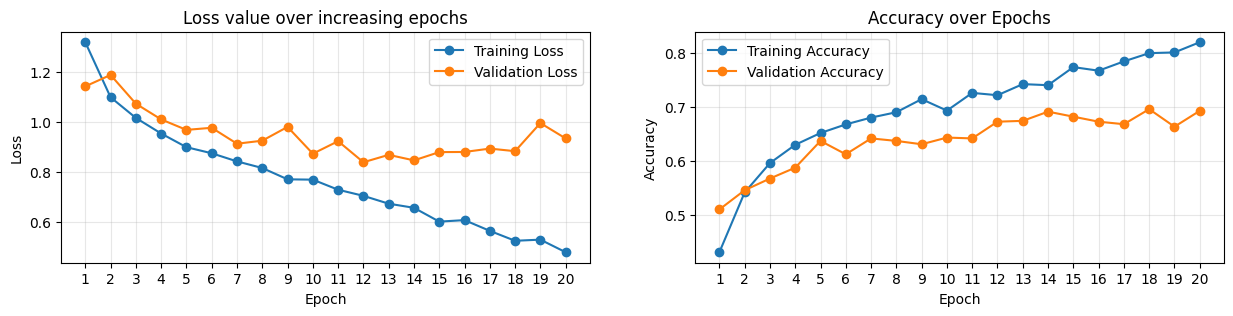

In [11]:
# Plot training vs validation loss and accuracy
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Test Set Evaluation
The final model is evaluated once on the unseen test set: **test loss 0.85, test accuracy 70.72%**. This is close to the validation accuracy, so the result is consistent. The classification report gives precision, recall and F1 for each flower class, and the confusion matrix shows which classes are confused.

In [12]:
# Final evaluation on the unseen test set
test_loss, test_acc =  validation(test_dl,model,loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.85 , Test Accuracy: 70.72%


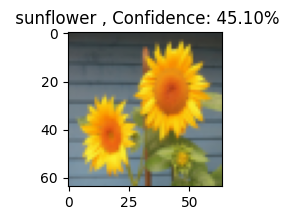

In [13]:
# Predict one test image and show the prediction
test_img, label = test_data[2]
img = test_img.view(-1,3,size,size).to(device)

model.eval()
with torch.no_grad():
    output = model(img)
pred = torch.softmax(output, dim=1)
confidence, index  = pred.max(-1)

plt.figure(figsize=(2,2))
plt.imshow(test_img.view(3,size,size).permute(1,2,0))
plt.title(f' {train_full.classes[index]} , Confidence: {confidence.item()*100:0.2f}%')
plt.show()

## 8. Saving and Loading the Model
Only the learned weights (`state_dict`) are saved to `model.pth` (about 6 MB). To reuse the model, the same architecture is rebuilt and the weights loaded into it. The identical summary confirms the model loaded correctly, and the prediction cell shows it working on a test image.

In [14]:
# Save only the learned weights (state_dict)
torch.save(model.state_dict(), 'model.pth')

In [15]:
# Rebuild the same architecture, load the saved weights, and check the summary matches
saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('model.pth'))
saved_model.eval()
summary(saved_model, (3, 64, 64))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
              ReLU-2           [-1, 64, 62, 62]               0
         MaxPool2d-3           [-1, 64, 31, 31]               0
            Conv2d-4          [-1, 128, 29, 29]          73,856
              ReLU-5          [-1, 128, 29, 29]               0
         MaxPool2d-6          [-1, 128, 14, 14]               0
            Conv2d-7          [-1, 128, 12, 12]         147,584
              ReLU-8          [-1, 128, 12, 12]               0
         MaxPool2d-9            [-1, 128, 6, 6]               0
          Flatten-10                 [-1, 4608]               0
           Linear-11                  [-1, 256]       1,179,904
             ReLU-12                  [-1, 256]               0
           Linear-13                    [-1, 5]           1,285
Total params: 1,404,421
Trainable param

## 9. Analysis and Discussion
- The model reaches 71.34% test accuracy on 5 classes, much better than random guessing (20%).
- Training accuracy (84%) is well above validation accuracy (about 66 to 69%), which indicates overfitting. The cause is a small dataset (about 3,000 training images) and a large fully connected layer (1.18M parameters), with no dropout or batch normalization.
- Augmentation helped control overfitting, but not completely.

## 10. Conclusions and Future Work
A custom CNN trained from scratch classified flowers with 71.34% test accuracy. Limitations: small dataset, low resolution (64x64), simple architecture, no regularization beyond augmentation.
Future work: add dropout and batch normalization, use stronger augmentation, train at a higher resolution, use a learning-rate scheduler or early stopping, and try transfer learning with a pretrained model such as ResNet.